In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
%matplotlib inline

In [12]:
df = pd.read_csv("bean-there-coffee-cleaned.csv")

# Section 1: Individual, Comparative, and Grouped Visualization

## 1. Charts

In [14]:
sales = df.copy()
sales["timestamp"] = pd.to_datetime(sales["timestamp"])
sales["store"] = (sales["store"].str.lower().str.replace(" ", "", regex=False)
                  .replace({"campusstore": "campus", "airportt2": "airport"})
                  .str.title())
sales = sales.drop_duplicates()
sales = sales[(sales["quantity"] > 0) & (sales["unit_price"] > 0)].copy()
sales["revenue"] = sales["unit_price"] * sales["quantity"]
sales["hour"] = sales["timestamp"].dt.hour
print(sales["store"].unique()) 
print(sales.shape)               

<ArrowStringArray>
['Airport', 'Campus', 'Downtown']
Length: 3, dtype: str
(7890, 13)


In [15]:
plt.rcParams.update({
    "figure.figsize": (8,5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "font.size": 11,
})

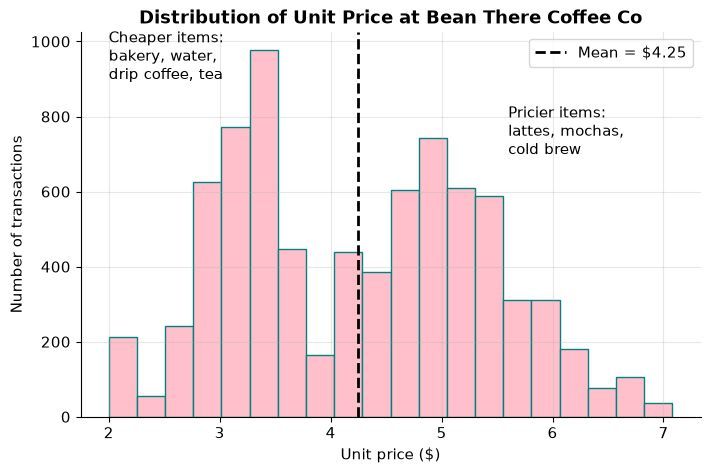

In [16]:
mean_price = sales["unit_price"].mean()

fig, ax = plt.subplots()
ax.hist(sales["unit_price"], bins=20, color="pink", edgecolor="teal")
ax.axvline(mean_price, color="black", ls="--", lw=2, label=f"Mean = \\${mean_price:.2f}")
ax.text(2.0, 900, "Cheaper items:\nbakery, water,\ndrip coffee, tea")
ax.text(5.6, 700, "Pricier items:\nlattes, mochas,\ncold brew")
ax.set_title("Distribution of Unit Price at Bean There Coffee Co")
ax.set_xlabel("Unit price (\\$)")
ax.set_ylabel("Number of transactions")
ax.legend()
plt.show()

 Explanation: Unit prices range from $2.00 to $7.08, with a mean of about $4.25. The histogram has two humps instead of one bell shape. The first peak is around $3.00 to $3.50 and the second is around $4.75 to $5.50. This is because the menu has two price tiers: bakery items, bottled water, drip coffee, tea, and espresso are mostly $2 to $4.80, while cold brew, cappuccino, chai latte, latte, and mocha are $4.20 to $7.08. Very few items cost over $6.50, which are large sizes of the specialty drinks. The $0 prices were removed first so they don’t distort the shape.

In [18]:
product = ["Cappucino", "Bottled Water", "Drip Coffee", "Latte"]

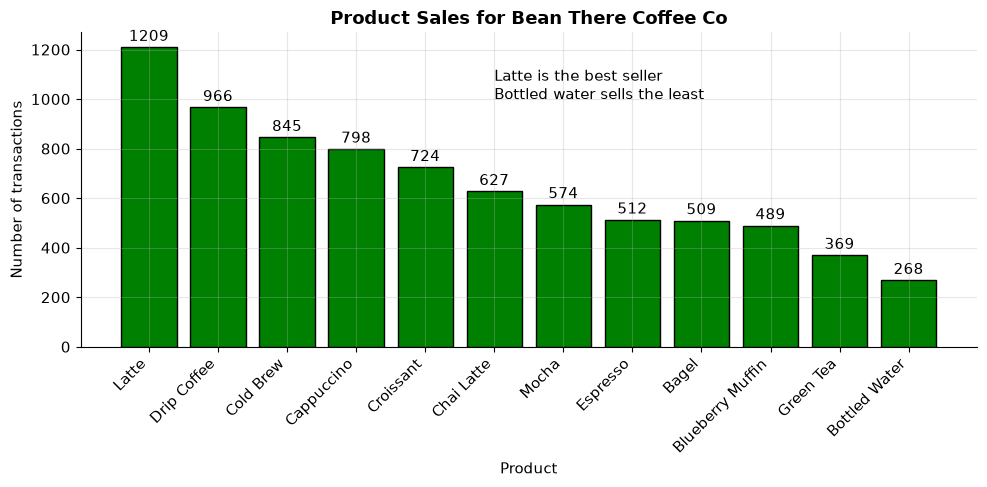

In [19]:
counts = sales["product"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color="green", edgecolor="black")
ax.bar_label(bars, padding=2)
ax.text(5, 1000, "Latte is the best seller\nBottled water sells the least")
ax.set_title("Product Sales for Bean There Coffee Co")
ax.set_xlabel("Product")
ax.set_ylabel("Number of transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Explanation: Latte is the best seller (about 1,209 transactions), followed by drip coffee (about 966) and cold brew (about 845). Bottled water is the least popular (about 268). Most of the top spots go to coffee drinks, so customers come mainly for coffee, with bakery items as a secondary purchase. Sales fall steadily from top to bottom, so a few popular drinks carry the menu.

In [21]:
import matplotlib.pyplot
%matplotlib inline
import seaborn as sns

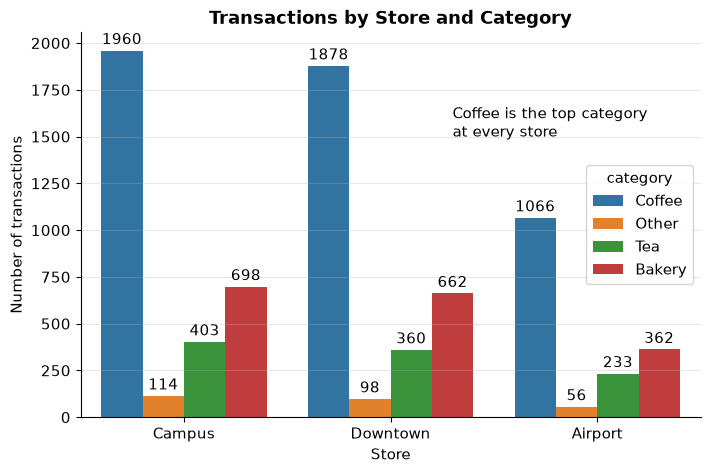

In [23]:
STORES = ["Campus", "Downtown", "Airport"]

fig, ax = plt.subplots()
sns.countplot(x="store", data=sales, hue="category", order=STORES, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=2)
ax.text(1.3, 1500, "Coffee is the top category\nat every store")
ax.set_title("Transactions by Store and Category")
ax.set_xlabel("Store")
ax.set_ylabel("Number of transactions")
sns.despine()
plt.show()

#### Explanation: Campus has the most transactions (3,175), then Downtown (2,998), and the Airport has the fewest (1,717). Within every store the order of categories is the same: coffee, bakery, tea, then other. Coffee makes up about 62% of sales at each location. Customers buy the same kinds of things everywhere, and the stores differ in how many customers they have.

## 2. Groupby Comparison

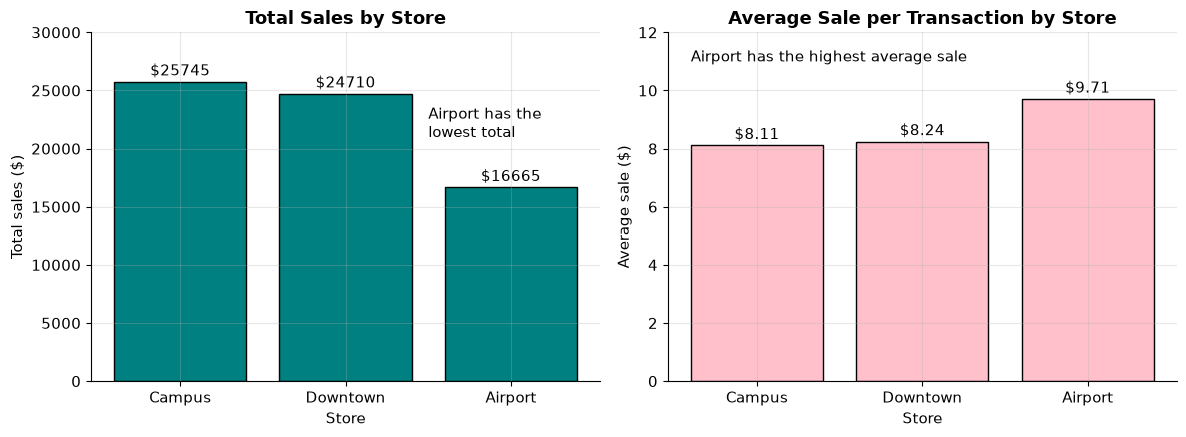

In [25]:
total_rev = sales.groupby("store")["revenue"].sum().reindex(STORES)
avg_rev = sales.groupby("store")["revenue"].mean().reindex(STORES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(total_rev.index, total_rev.values, color="teal", edgecolor="black")
axes[0].bar_label(bars, fmt="\\$%.0f", padding=2)
axes[0].text(1.5, 21000, "Airport has the\nlowest total")
axes[0].set_ylim(0, 30000)
axes[0].set_title("Total Sales by Store")
axes[0].set_xlabel("Store")
axes[0].set_ylabel("Total sales (\\$)")

bars = axes[1].bar(avg_rev.index, avg_rev.values, color="pink", edgecolor="black")
axes[1].bar_label(bars, fmt="\\$%.2f", padding=2)
axes[1].text(-0.4, 11, "Airport has the highest average sale")
axes[1].set_ylim(0, 12)
axes[1].set_title("Average Sale per Transaction by Store")
axes[1].set_xlabel("Store")
axes[1].set_ylabel("Average sale (\\$)")

plt.tight_layout()
plt.show()

Explanation: Explanation: Campus has the highest total sales (about $25,745), closely followed by Downtown (about $24,710). The Airport is far behind at about $16,665, which fits its lower transaction count. Average sale per transaction shows the opposite pattern: the Airport is highest (about $9.71), while Campus ($8.11) and Downtown ($8.24) are almost the same. Airport customers don’t buy more items (about 2 per transaction at every store). The difference comes from price, since the average unit price at the Airport is about $4.92 versus about $4.06 elsewhere. So the Airport earns less overall because it has fewer customers, but each customer is worth more. These totals are before discounts.

# Section 2: Relationship Visualizations

## Scatter Plot

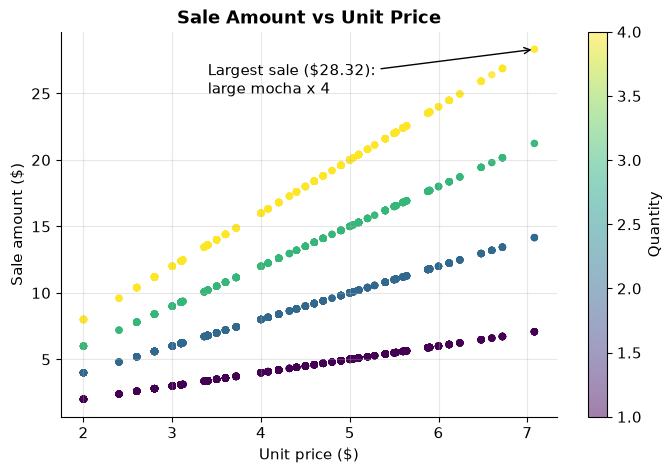

In [26]:
fig, ax = plt.subplots()
sc = ax.scatter(sales["unit_price"], sales["revenue"], c=sales["quantity"],
                cmap="viridis", alpha=0.5, s=18)
fig.colorbar(sc, ax=ax, label="Quantity")
ax.annotate("Largest sale (\\$28.32):\nlarge mocha x 4", xy=(7.08, 28.32), xytext=(3.4, 25),
            arrowprops=dict(arrowstyle="->"))
ax.set_title("Sale Amount vs Unit Price")
ax.set_xlabel("Unit price (\\$)")
ax.set_ylabel("Sale amount (\\$)")
plt.show()

#### Explanation: There is a clear positive trend: higher unit prices lead to bigger sale amounts. The points form four straight bands, one for each quantity (1 to 4), because sale amount is exactly unit price times quantity. Each band rises with price, and a higher quantity lifts the whole band. There are no true outliers. The largest sale ($28.32, a large mocha times 4) is simply the highest price times the highest quantity. The $0 prices and negative quantities were removed during cleaning, since they would have appeared as outliers.

## Corrrelation Heatmap

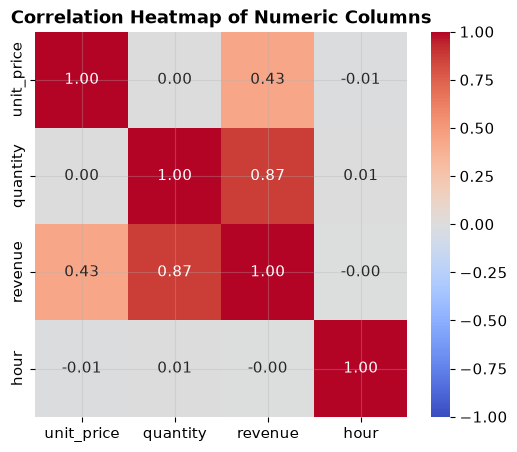

In [27]:
corr = sales[["unit_price", "quantity", "revenue", "hour"]].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Columns")
plt.show()

#### Explanation: The strongest relationship is between quantity and revenue (0.87), then unit price and revenue (0.43). Both make sense because revenue is calculated from them. Quantity matters more because it ranges from 1 to 4, while prices only vary from about $2 to $7. The correlation between unit price and quantity is about 0.00, so customers don’t buy more or fewer items when the item costs more. The hour of the day is also essentially uncorrelated with everything (between -0.01 and 0.01), so time of day doesn’t change what people spend. Since revenue is built from the other columns, the heatmap shows no surprising hidden relationships.